# Whole-hierarchy robustness: useful local peers, but an incremental H0 advantage?

**Finding:** stable local bank, energy, and staples branches do exist. The six-group cut obscured some of them. However, average linkage recovers essentially the same robust local sets, and H0 does not establish a broadly stronger peer representation here.

This is a structural follow-up requested after the original evaluation was examined. No P&L threshold was selected, and no trading, signal, holding, or fee model was changed. All prior strategy results are preserved. Use **TDA (conda)**; the notebook reads local outputs. [Full findings and assumptions](experiments/equity_h0_scale_robustness/README.md), [source](experiments/equity_h0_scale_robustness.py), [original H0 pilot](equity_h0_peers.ipynb).

## Fixed experiment

Every hierarchy cut K=1–30 is reported. The primary history is 120 standardized SPY-residual return observations. We assess 100- and 140-day histories, a five-session-older 120-day history, and 40 five-session-block resamples with the SPY regression re-estimated.

There are 93 development anchors and 34 later anchors. Each uses a subsequent nonoverlapping 20-session target block and its already estimated SPY coefficients to measure future residual correlation. Prior windows overlap, so the blocks do not guarantee independence. Crossing the 2024 boundary is excluded.

At each cut, 250 random relabelings preserve cluster sizes; the same stock permutation across cuts preserves nesting. Mean-curve uncertainty uses 1,000 six-anchor block resamples, with paired method comparisons and approximate simultaneous bands across cuts. No fresh holdout is claimed.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
project_candidates = [Path.cwd(), Path.cwd() / "Senior-Fall" / "TDA_Research", *Path.cwd().parents]
project = next(p for p in project_candidates if (p / "START_HERE.md").is_file() and (p / "equity").is_dir())
root = project / "equity"
out = root / "experiments" / "equity_h0_scale_robustness"
summary = json.loads((out / "summary.json").read_text())
curves = pd.read_csv(out / "cut_summary.csv")
paired = pd.read_csv(out / "paired_method_differences.csv")
print("Anchor counts:", summary["anchor_counts"])
print("No trading changes:", not summary["configuration"]["trading_changes"])
print("No P&L parameter selection:", not summary["configuration"]["parameter_selection_by_PnL"])
print("Local branch diagnostic:", summary["configuration"]["stable_local_branch"])

Anchor counts: {'development': 93, 'evaluation': 34}
No trading changes: True
No P&L parameter selection: True
Local branch diagnostic: {'size_min': 3, 'size_max': 8, 'exact_bootstrap_recovery_min': 0.75, 'window_perturbation_recovery_min': 0.6666666666666666}


## 1. A finer cut trades giant components for singleton stocks

The six-group partition was not the only imbalanced cut. Single linkage/H0 has larger broad components than average linkage at many cut counts. At K=15, the later H0 largest group averages about seven stocks, but about ten stocks are singletons. Finer cuts expose local peers without necessarily covering the whole universe with useful baskets.

K=1 and K=30 have trivial balance properties. Their within-minus-between correlation is undefined because one type of pair does not exist; those endpoint scores are missing, not zero. If used as group-neutral portfolio constraints, singleton labels would force those holdings to zero. No such new portfolio was backtested here.

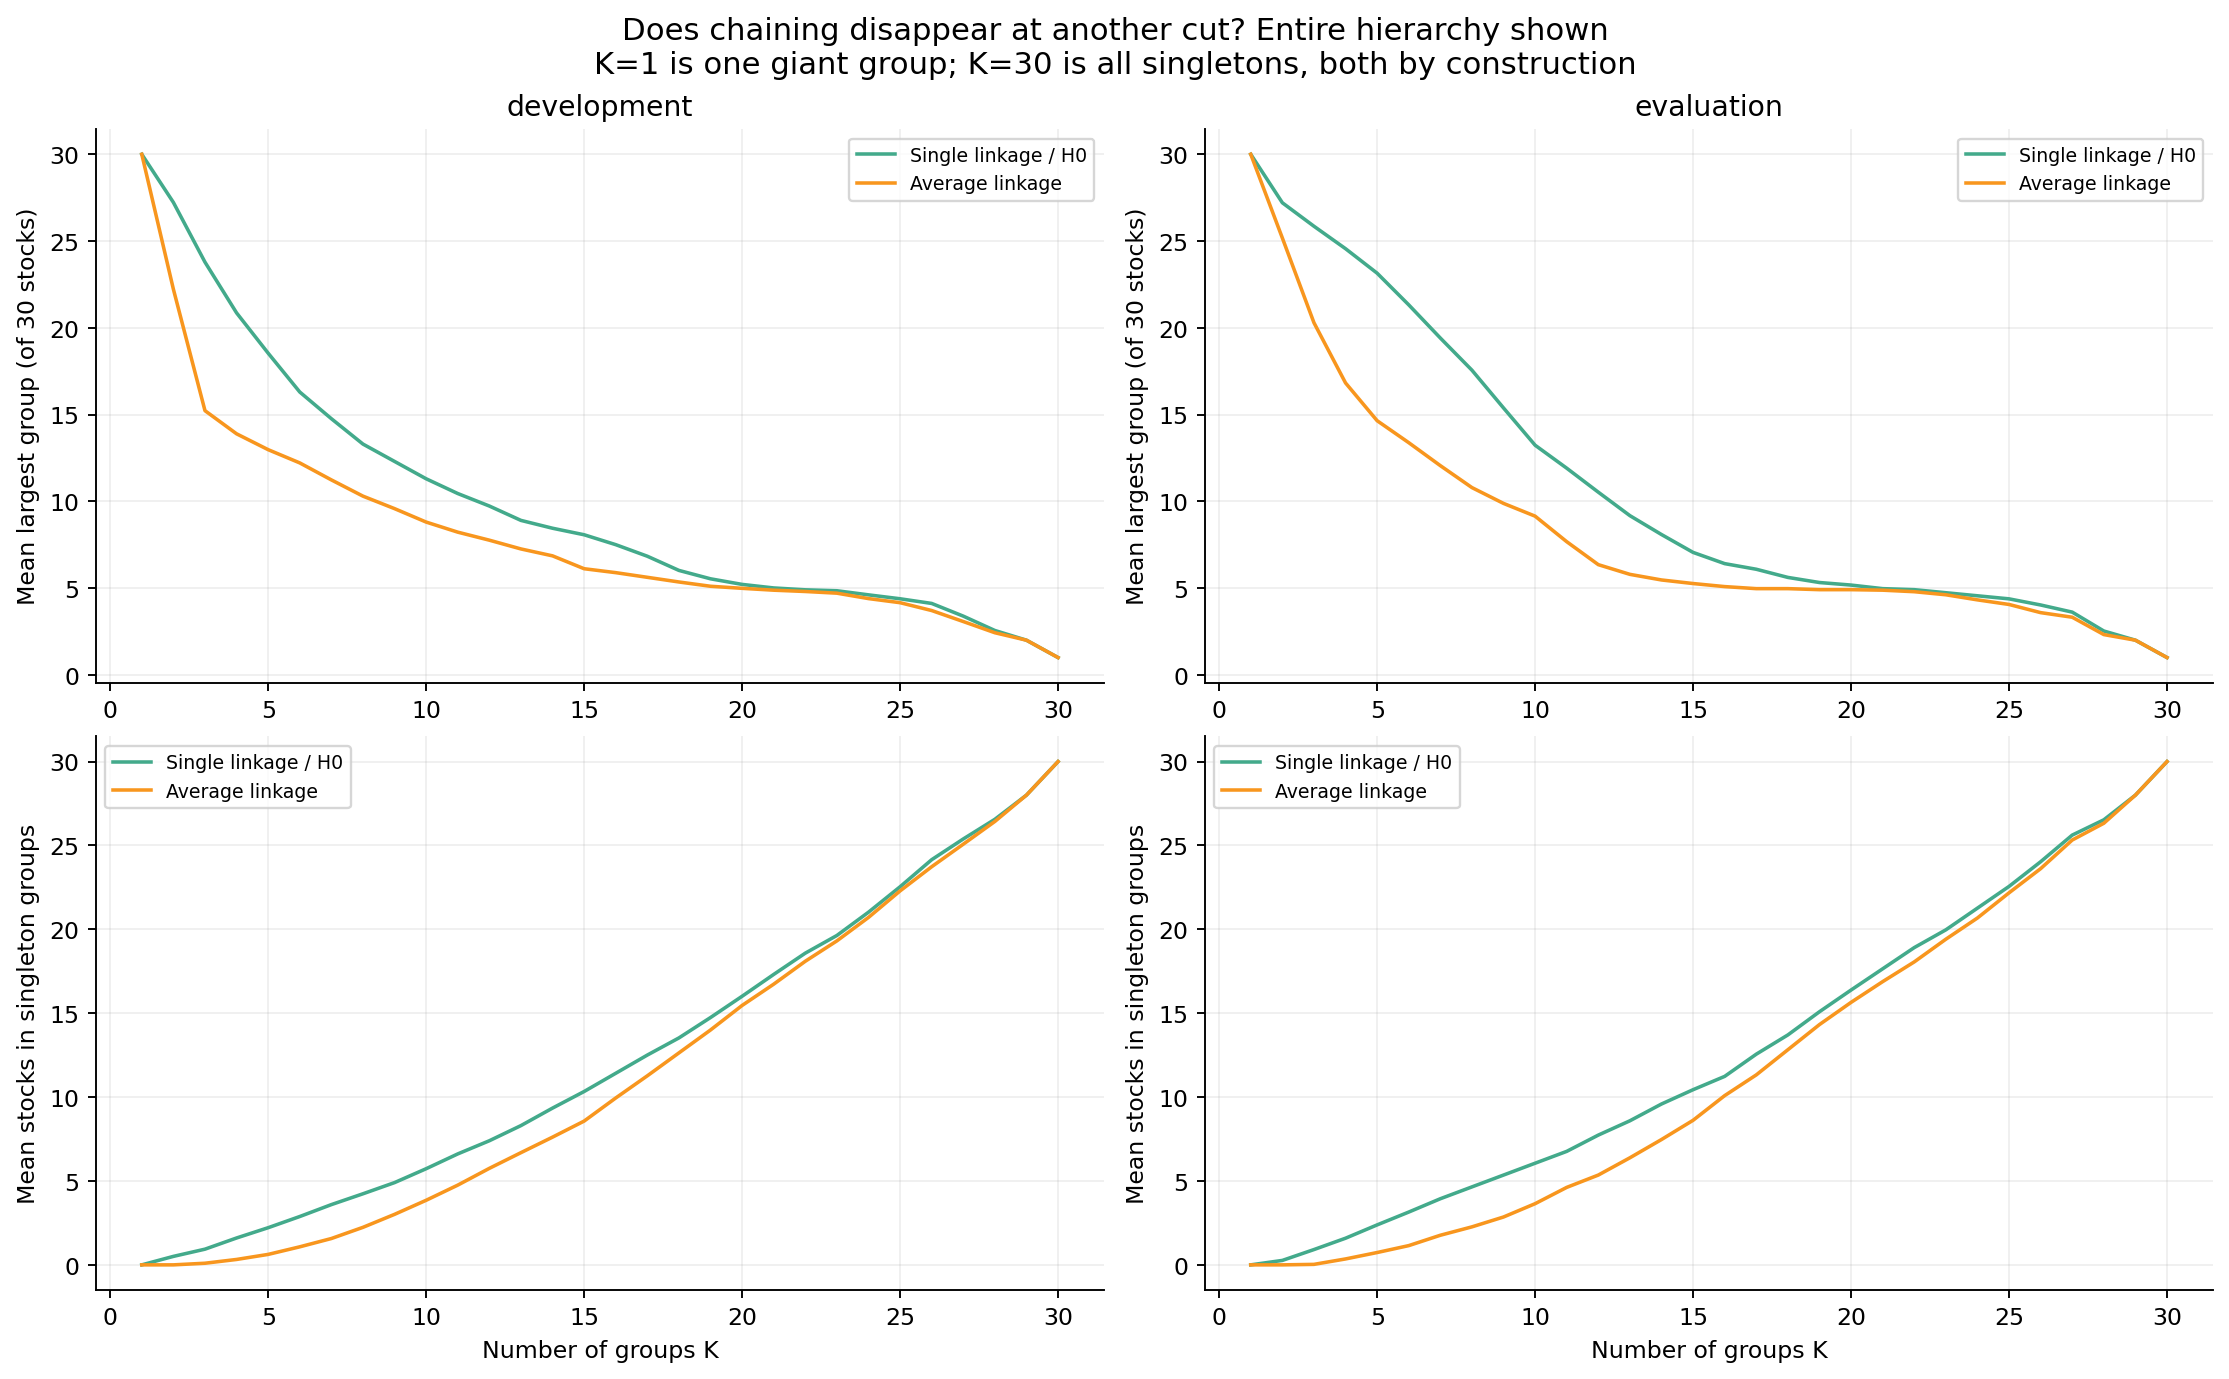

,period,method,groups,mean_largest_group,mean_singleton_stocks
5,development,Single_H0,6,16.301,2.882
9,development,Single_H0,10,11.301,5.731
14,development,Single_H0,15,8.075,10.333
19,development,Single_H0,20,5.215,16.011
24,development,Single_H0,25,4.387,22.538
35,development,Average,6,12.215,1.075
39,development,Average,10,8.806,3.849
44,development,Average,15,6.118,8.570
49,development,Average,20,4.989,15.462
54,development,Average,25,4.161,22.290


In [2]:
display(Image(filename=str(out / "01_balance_all_cuts.png")))
display(curves.loc[curves.groups.isin([6, 10, 15, 20, 25]), ["period", "method", "groups", "mean_largest_group", "mean_singleton_stocks"]].round(3))

## 2. Stability depends on how strongly we perturb the history

The upper panels average agreement under the three window changes. The lower panels assess block-resampled historical observations. ARI compares partitions independently of arbitrary label numbering; one is identical, zero is chance-adjusted agreement.

Adjacent 120-day windows share 119 observations, so their high agreement in the earlier notebook was an optimistic sampling-robustness picture. The stronger perturbations give lower agreement. Neither method is universally more stable across periods and cuts. These resamples are diagnostics, not additional independent market histories or proof of an economic regime.

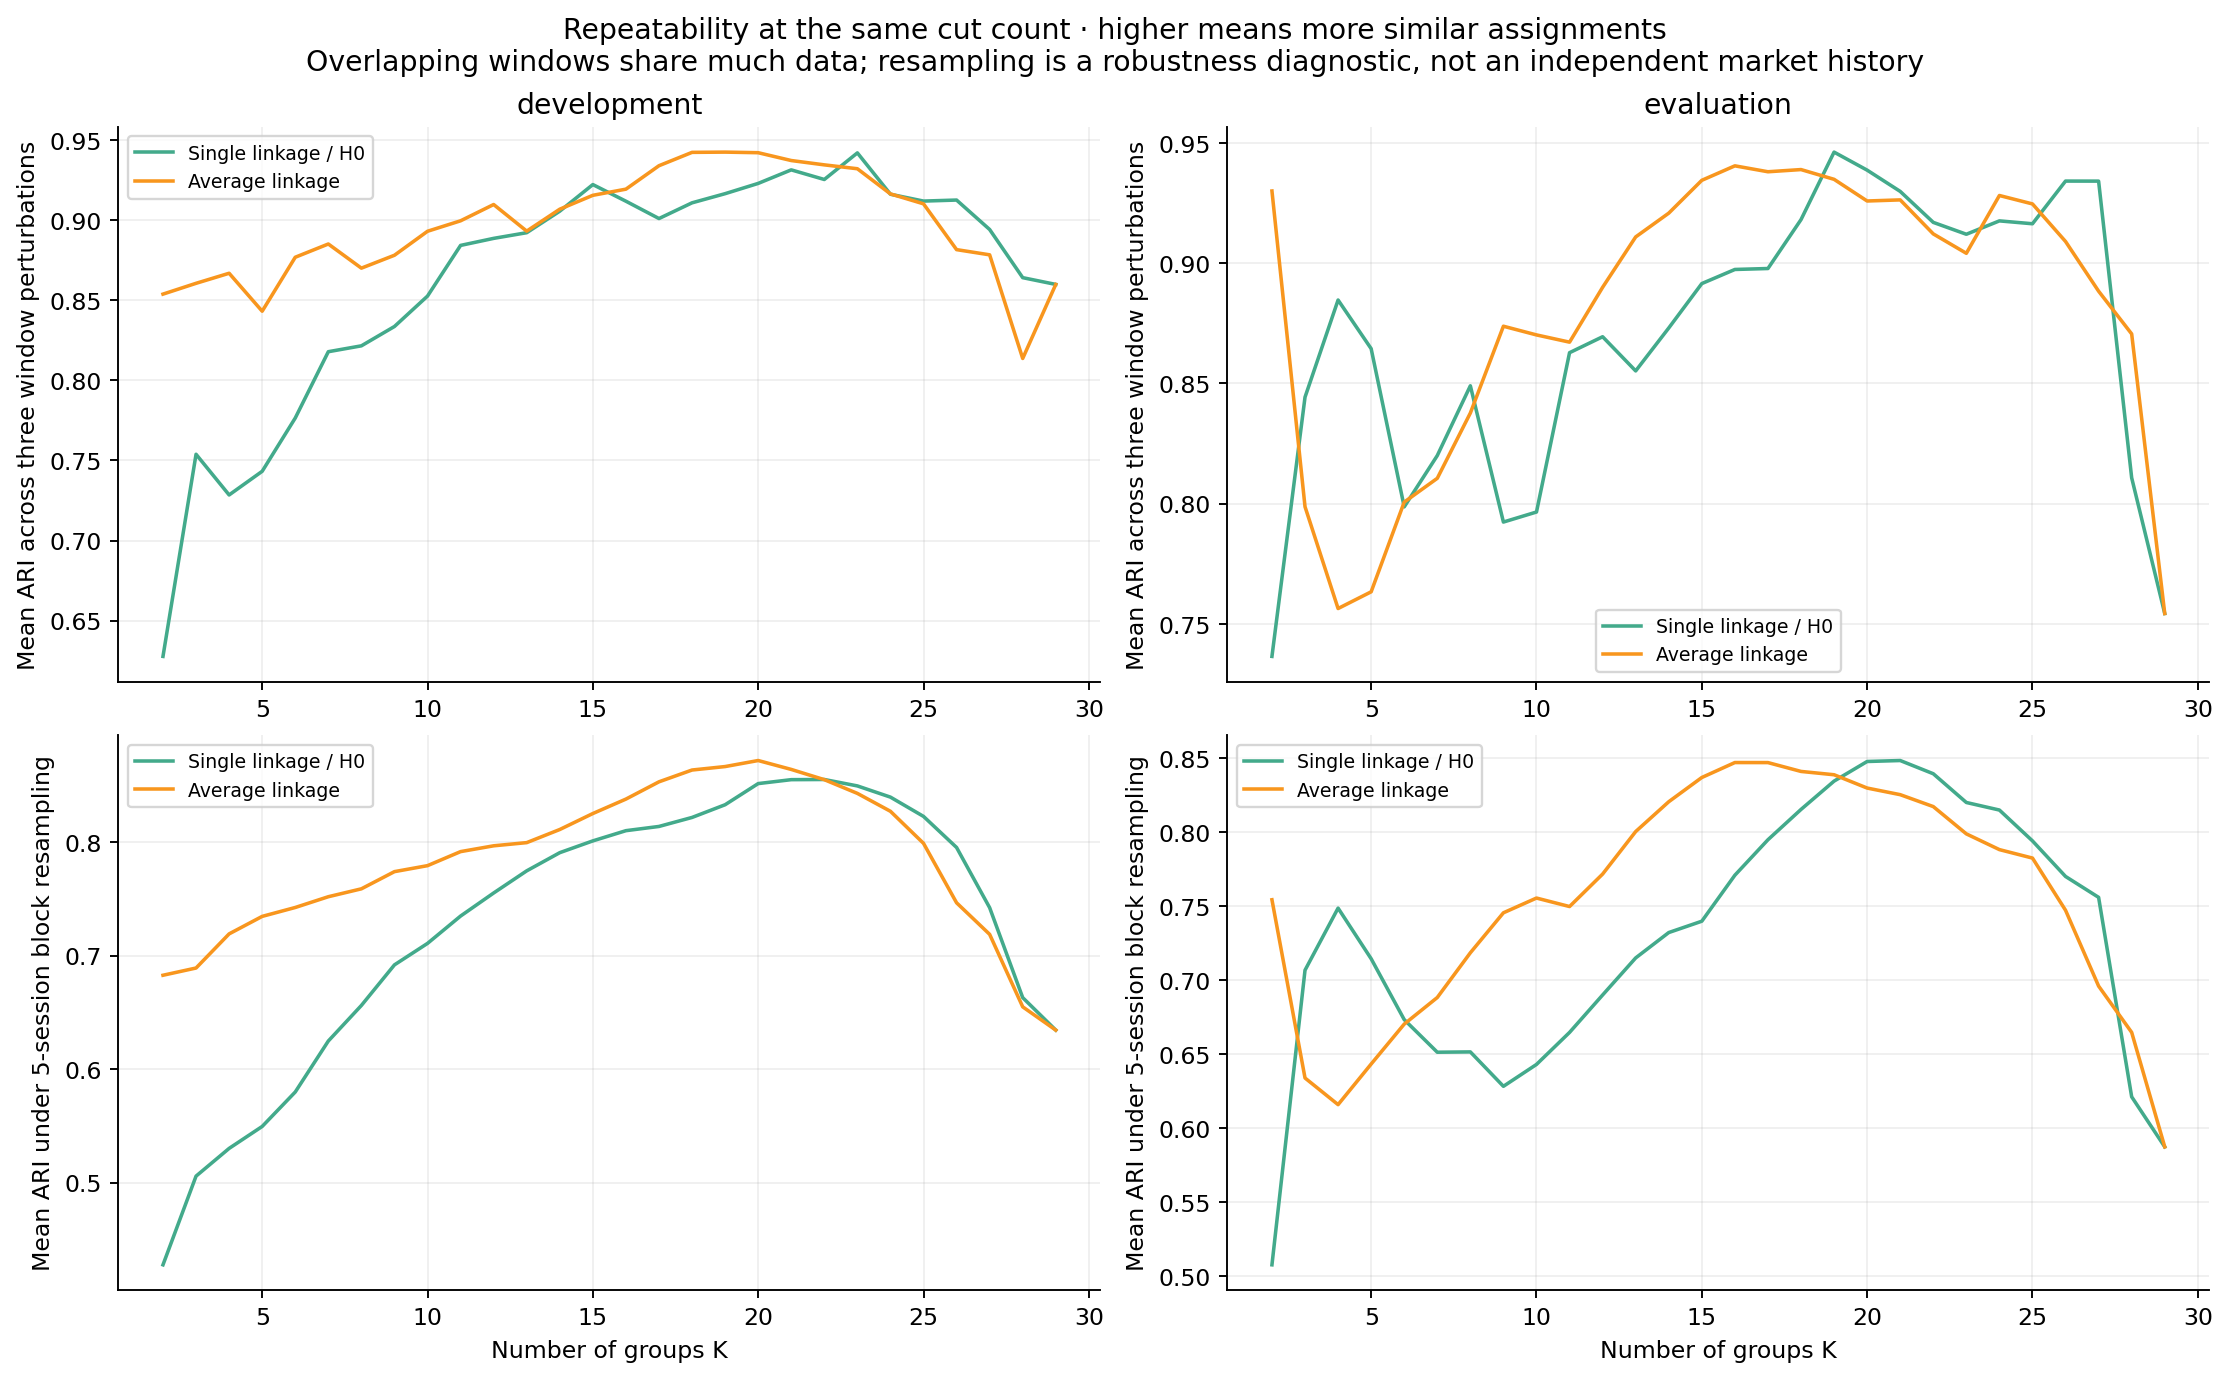

,period,method,mean_100_ARI,mean_140_ARI,mean_shift_ARI,mean_bootstrap_ARI
5,development,Single_H0,0.761,0.766,0.802,0.580
35,development,Average,0.869,0.863,0.899,0.742
65,evaluation,Single_H0,0.755,0.776,0.866,0.673
95,evaluation,Average,0.758,0.806,0.838,0.670


In [3]:
display(Image(filename=str(out / "02_stability_all_cuts.png")))
display(curves.loc[curves.groups.eq(6), ["period", "method", "mean_100_ARI", "mean_140_ARI", "mean_shift_ARI", "mean_bootstrap_ARI"]].round(3))

## 3. Both methods contain structure beyond same-size random groups

Both future-coherence curves exceed the matched random reference envelope at all nondegenerate cuts in this run. That supports repeatable relationships in this basket, not a unique topological advantage or return forecast.

The paired difference is more informative than looking for overlap between two separate intervals. Average linkage is favored across many broader cuts. One later exception favors H0 at K=27 (difference about +0.0189), but about 25.6 stocks are singletons there. It was not selected as a new model. K=29 selects the closest pair in both methods and they agree.

Absolute coherence increases at fine cuts because the within-group average focuses on fewer strong relationships. This is not a reason to maximize K. Solid bands are approximate simultaneous mean-curve bands across cuts; hatched bands are size-matched random references. They do not cover all research decisions. Only 34 later target blocks are available.

development cuts favoring H0 under the simultaneous bands: []
development cuts favoring average linkage under the simultaneous bands: [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
evaluation cuts favoring H0 under the simultaneous bands: [27]
evaluation cuts favoring average linkage under the simultaneous bands: [6, 7, 8, 9, 10, 11, 12, 13, 14, 24]


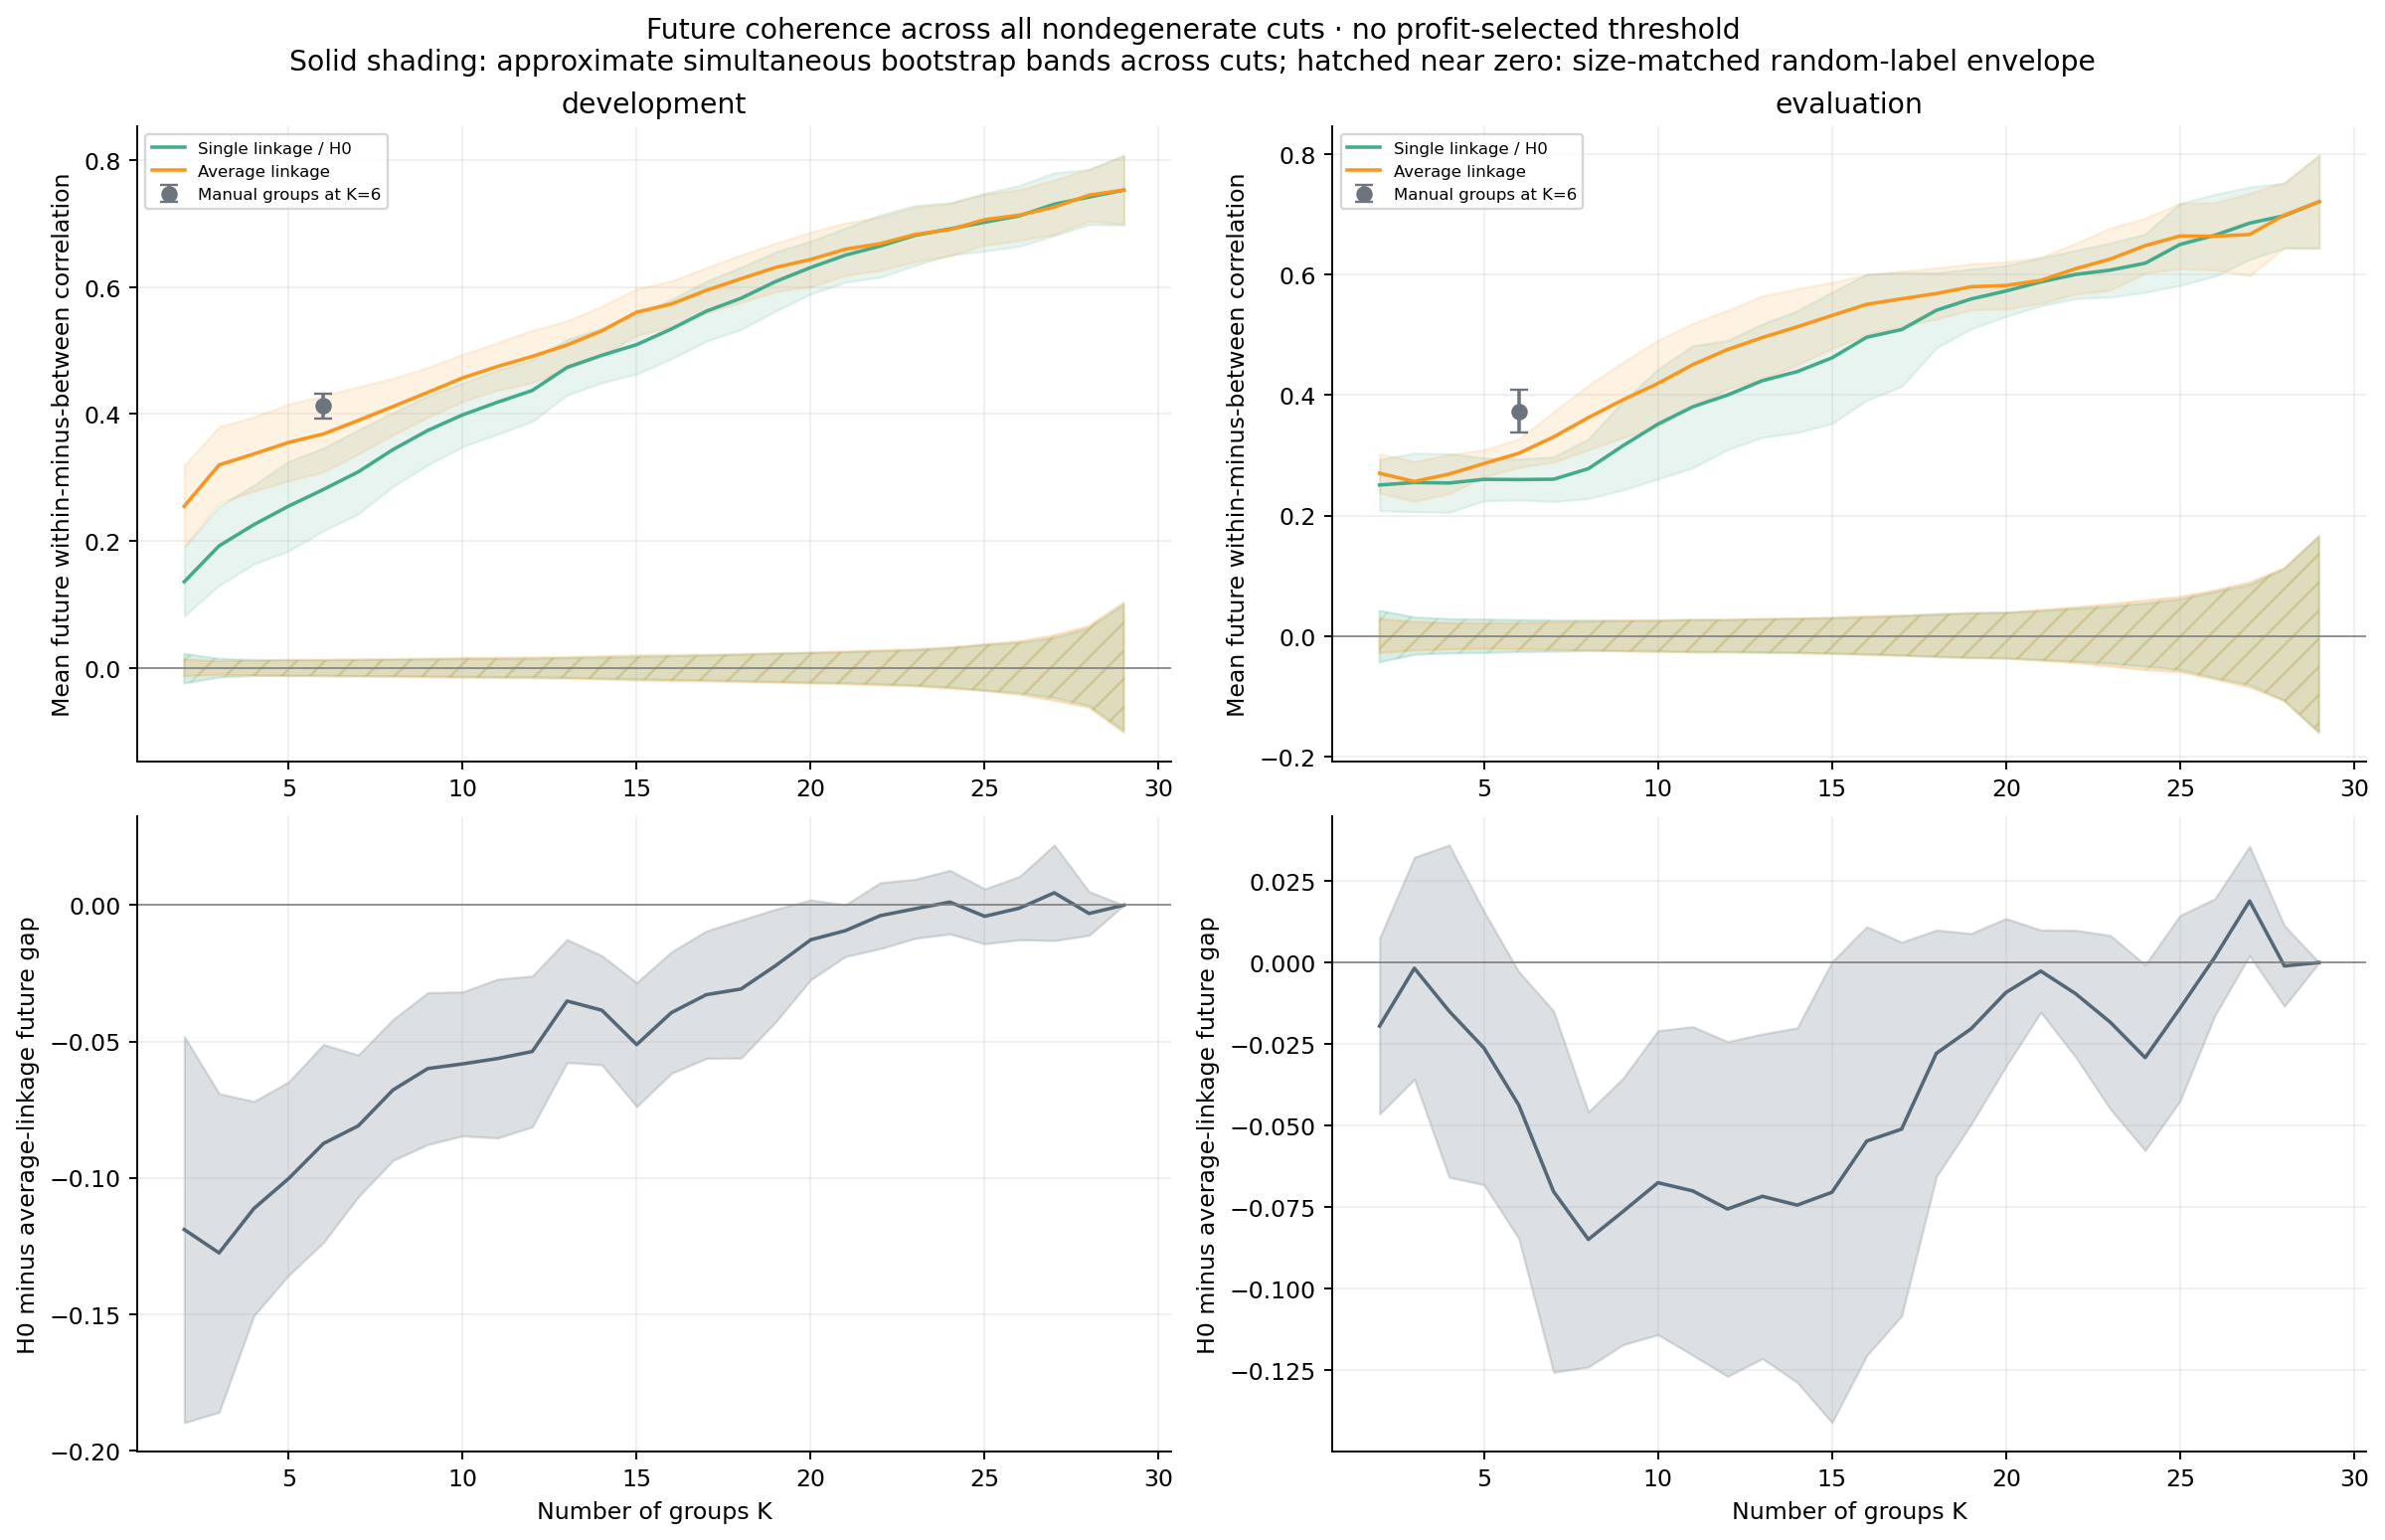

,period,groups,H0_minus_average_gap,point95_low,point95_high,sim95_low,sim95_high
53,evaluation,27,0.01886,0.00771,0.03041,0.00211,0.03562


,method,groups,mean_largest_group,mean_singleton_stocks,future_gap_mean
86,Single_H0,27,3.618,25.618,0.686
116,Average,27,3.324,25.324,0.667


In [4]:
display(Image(filename=str(out / "03_future_coherence_and_random_controls.png")))
for period in ["development", "evaluation"]:
    frame = paired.loc[paired.period.eq(period)]
    print(period, "cuts favoring H0 under the simultaneous bands:", frame.loc[frame.sim95_low.gt(0), "groups"].tolist())
    print(period, "cuts favoring average linkage under the simultaneous bands:", frame.loc[frame.sim95_high.lt(0), "groups"].tolist())
display(paired.loc[paired.period.eq("evaluation") & paired.groups.eq(27)].round(5))
display(curves.loc[curves.period.eq("evaluation") & curves.groups.eq(27), ["method", "groups", "mean_largest_group", "mean_singleton_stocks", "future_gap_mean"]].round(3))

## 4. Named branches can be stable even when one global cut is poor

Here a branch is an exact member set appearing anywhere in the hierarchy. We assess all nonroot internal branches; overlapping parent/child sets are retained. A past-only diagnostic flags sets of 3–8 stocks with at least 75% exact bootstrap recovery and recovery in at least two of three window perturbations. These are fixed diagnostic thresholds, not an optimized selector.

Examples include XOM/CVX/COP/EOG/SLB, JPM/BAC/C/GS/MS, and PG/KO/PEP. Such named groups are interpretable, without proving why they co-move or that their deviations reverse. Examples below are ordered by past stable-occurrence counts, not future returns.

We also check whether the **same selected H0 sets** appear in average linkage. All 126 later stable H0 branch occurrences appear there, and 119 are stable there as well. Occurrences repeat across anchors and may be nested; they are not 126 independent discoveries.

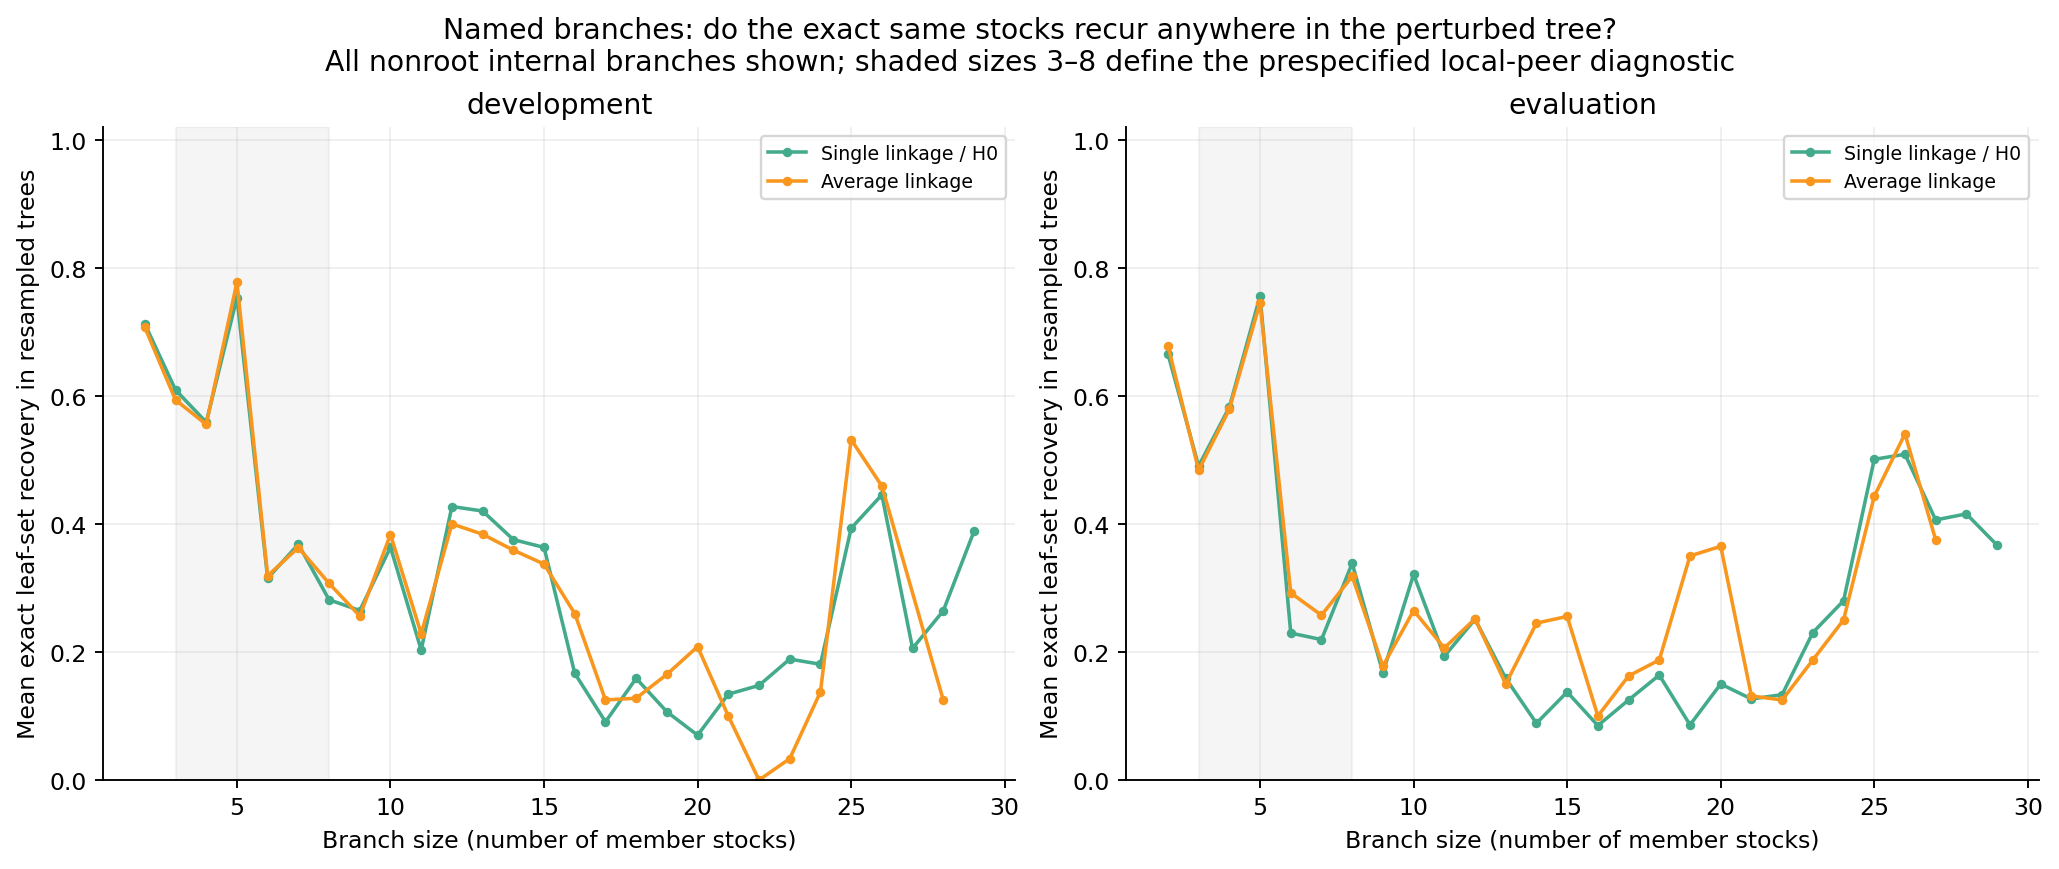

,period,stable_H0_occurrences,also_average_branch,also_stable_average_branch
0,development,391,388,352
1,evaluation,126,126,119


,period,method,stocks,size,observed_anchors,mean_bootstrap_recovery,mean_window_recovery,stable_candidate_anchors,mean_future_local_gap
1323,evaluation,Single_H0,"XOM, CVX, COP, EOG, SLB",5,34,0.960,1.000,33,0.648
1212,evaluation,Single_H0,"JPM, BAC, C, GS, MS",5,34,0.935,1.000,31,0.558
1322,evaluation,Single_H0,"XOM, CVX, COP, EOG",4,33,0.843,0.990,25,0.711
1310,evaluation,Single_H0,"PG, KO, PEP",3,28,0.760,0.976,16,0.485
1307,evaluation,Single_H0,"PFE, MRK, ABBV, AMGN",4,10,0.712,0.933,6,0.443
1115,evaluation,Single_H0,"BAC, C, GS, MS",4,17,0.621,0.863,3,0.478
1320,evaluation,Single_H0,"XOM, COP, EOG",3,17,0.537,0.804,3,0.635
1210,evaluation,Single_H0,"JPM, BAC, C",3,8,0.581,0.750,3,0.581
1283,evaluation,Single_H0,"JPM, BAC, GS, MS",4,6,0.658,0.889,2,0.570
1165,evaluation,Single_H0,"JNJ, PFE, MRK, ABBV, AMGN, PG, KO, PEP",8,14,0.511,0.881,1,0.398


,period,method,local_branches,stable_local_branches
0,development,Average,13.043,4.613
1,development,Single_H0,12.559,4.204
2,evaluation,Average,13.206,4.029
3,evaluation,Single_H0,11.824,3.706


In [5]:
display(Image(filename=str(out / "04_branch_recovery_by_size.png")))
branches = pd.read_csv(out / "all_internal_branches.csv")
assert branches.stable_local_candidate.dtype == bool
rows = []
for period in ["development", "evaluation"]:
    period_frame = branches.loc[branches.period.eq(period)]
    h0 = period_frame.loc[period_frame.method.eq("Single_H0") & period_frame.stable_local_candidate]
    average = period_frame.loc[period_frame.method.eq("Average")]
    all_sets = set(zip(average.anchor, average.stocks))
    stable_average = average.loc[average.stable_local_candidate]
    stable_sets = set(zip(stable_average.anchor, stable_average.stocks))
    rows.append({"period": period, "stable_H0_occurrences": len(h0),
                 "also_average_branch": sum((a, s) in all_sets for a, s in zip(h0.anchor, h0.stocks)),
                 "also_stable_average_branch": sum((a, s) in stable_sets for a, s in zip(h0.anchor, h0.stocks))})
overlap = pd.DataFrame(rows)
overlap.to_csv(out / "branch_overlap_summary.csv", index=False)
display(overlap)
catalogue = pd.read_csv(out / "named_branch_catalogue.csv")
examples = catalogue.loc[catalogue.period.eq("evaluation") & catalogue.method.eq("Single_H0") & catalogue["size"].between(3, 8) & catalogue.stable_candidate_anchors.gt(0)]
display(examples.sort_values(["stable_candidate_anchors", "observed_anchors"], ascending=False).head(10).round(3))
display(pd.DataFrame(summary["stable_branch_counts"]).round(3))

## Decision

**Yes to local peer structure; no compelling incremental H0 advantage established.** The six-group cut hid useful branches, but average linkage recovers essentially the same robust local sets and generally has better future coherence at broader cuts. The narrow fine-cut exception is recorded rather than hidden; it is not promoted into a strategy.

Keep the labeled hierarchy and branch-recovery diagnostic as a research result. Do not add another H0 trading variation on this basket merely to improve historical profit. If equity work continues, use manual and average-linkage peers as strong comparators, freeze any branch-to-exposure rule, and test broader-universe generalization separately. H1 or another representation needs its own scientific distinction. The original trading results and pre-fee reporting convention are unchanged.

In [6]:
print("Controls:", summary["checks"])
print("Input return snapshot SHA-256:", summary["input_returns_sha256"])
print("Source SHA-256:", summary["source_sha256"])
print("This notebook contains structural outcomes only; no new P&L was selected or computed.")

Controls: {'fast_ARI_matches_sklearn': True, 'degenerate_cut_gaps_undefined': True, 'all_cuts_have_requested_group_count': True, 'complete_tree_has_28_nonroot_branches': True, 'random_labels_preserve_every_cluster_size': True, 'future_blocks_nonoverlapping': True, 'past_only_branch_candidate_selection': True, 'all_cut_endpoints_reported_but_not_scored_for_coherence': True}
Input return snapshot SHA-256: 2f1b0d66d17db0faeeed7c30b3fafc4685e204e2d79bf25962a271dcdebe42e9
Source SHA-256: 776611aa62c2f9b5798c2d9ded45a572cc86d233b9c7c3c07a7e411373527333
This notebook contains structural outcomes only; no new P&L was selected or computed.
